# 00 · Getting started with `latent-factor-models`

This notebook is the entry point. It explains **installation, data formats, the
common interface shared by all seven estimators, every output they produce,
parallel execution and the command line**. The model notebooks `01`-`09` then go
into each method in depth.

| Notebook | Topic |
|---|---|
| 01 | PCA (statistical factors, number of factors) |
| 02 | RP-PCA (Lettau-Pelger): choosing the risk-premium weight γ |
| 03 | SPCA (Giglio-Xiu-Zhang): risk premia of weak factors |
| 04 | IPCA (Kelly-Pruitt-Su): characteristics-instrumented betas, bootstrap tests |
| 05 | XS-target PCA (Bryzgalova et al.) |
| 06 | TS-target PCA (alpha / mean targets) |
| 07 | XS-TS-target PCA and two-dimensional tuning |
| 08 | Experiment engine, parallel backends, configuration files, CLI |
| 09 | Risk-premium inference: Giglio-Xiu three-pass estimator |

### How to run this notebook

```bash
pip install -e ".[notebooks]"        # package + jupyter, matplotlib, pandas
jupyter lab examples/                 # or: jupyter notebook examples/
```

All data are **synthetic with known ground truth** (generated by
`lfm.simulate_factor_returns` / `lfm.simulate_ipca_panel`), so every cell runs
offline in seconds and estimates can be compared with the truth. To use your
own data, replace the simulation cell by a `pandas.DataFrame` of excess returns
(dates x assets); every estimator accepts DataFrames directly.

In [1]:
# Setup: imports, plotting defaults and reproducibility
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import latent_factor_models as lfm

np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.figsize": (8, 3.6), "axes.grid": True, "grid.alpha": 0.3})
print("latent-factor-models", lfm.__version__)

latent-factor-models 0.1.0


## 1. Data formats

| Input | Shape | Container | Used by |
|---|---|---|---|
| excess returns $R$ | $T\times N$ (dates × assets) | array or `DataFrame` | all return-based models |
| observable factors $G$ | $T\times d$ | `factors=` | SPCA, three-pass, alpha target (as reference) |
| cross-sectional target $\Lambda$ | $N\times L$ | `xs_target=` | XS / XS-TS target PCA |
| time-series target $G^{TS}$ | $T\times J$ | `ts_target=` | TS / XS-TS target PCA (`ts_target="given"`) |
| macro innovations $Y$ | $T\times L$ | `macro=` | XS target `"macro"` |
| characteristic panel $Z$ | $T\times N\times L$ | `CharacteristicPanel` | IPCA |

Everything is bundled in a validated `FactorData` container; the estimators
build it for you from keyword arguments. Missing values must be handled first
for the balanced-panel models (`FactorData.dropna`); IPCA handles unbalanced
panels natively.

In [2]:
sim = lfm.simulate_factor_returns(T=600, N=100, seed=0)
dates = pd.date_range("1975-01-31", periods=600, freq="ME")
R = pd.DataFrame(sim.returns, index=dates, columns=[f"asset_{i}" for i in range(100)])
G = pd.DataFrame(sim.observable, index=dates, columns=["market_proxy", "useless"])
R.iloc[:3, :5]

,asset_0,asset_1,asset_2,asset_3,asset_4
1975-01-31,5.9901,6.0001,0.8041,-0.1255,0.2643
1975-02-28,7.3342,-0.8500,-0.9478,-3.0392,-3.4314
1975-03-31,2.6775,-2.7690,0.3907,7.1247,14.6336


## 2. The common interface

Every estimator follows the same pattern (scikit-learn style):

```python
model = lfm.<Model>(n_factors=K, **hyper_parameters)   # specification
model.fit(R, **side_information)                         # estimation
model.<attribute>_                                       # fitted outputs
model.evaluate(R_new)                                    # (out-of-sample) metrics
model.clone(**changes)                                   # unfitted copy for CV / engines
```

In [3]:
model = lfm.RPPCA(n_factors=3, gamma=10).fit(R)
model

RPPCA(n_factors=3, gamma=10, standardize=False)

## 3. Outputs of return-based models (PCA, RP-PCA, target PCA, SPCA)

| Attribute / method | Shape | Meaning |
|---|---|---|
| `weights_` | $N\times K$ | factor portfolio weights $\hat\omega$ (factors are portfolios) |
| `factors_` | $T\times K$ | in-sample factors $F=R\hat\omega$ (keep their means = risk premia) |
| `loadings_` | $N\times K$ | time-series OLS betas $\hat\beta$ |
| `intercepts_` | $N$ | time-series intercepts = in-sample pricing errors $\alpha$ |
| `eigenvalues_` | $K$ | leading eigenvalues of the model's operator |
| `transform(R)` | $T'\times K$ | factors for new returns with fixed weights |
| `fitted_values(R)`, `residuals(R)` | $T'\times N$ | systematic / idiosyncratic components |
| `evaluate(R)` | dict | Sharpe ratio, RMS α, unexplained variation, total $R^2$ |
| `projection_loadings()` | $N\times K$ | Lettau-Pelger out-of-sample pricing loadings |
| spectral models: `spectrum()`, `absorption_ratio()`, `variance_signal()`, `operator_` | | eigen-diagnostics |
| target models: `target_metrics()` | dict | XS-metric (per factor and SDF), TS-metric |

In [4]:
print("weights  ", model.weights_.shape)
print("factors  ", model.factors_.shape)
print("loadings ", model.loadings_.shape)
print("eigenvals", model.eigenvalues_)
pd.Series(model.evaluate(), name="in-sample")

weights   (100, 3)
factors   (600, 3)
loadings  (100, 3)
eigenvals [16.6846  4.2039  1.0469]


sharpe_ratio             0.3742
rms_alpha                0.1221
unexplained_variation    0.3373
total_r2                 0.7058
Name: in-sample, dtype: float64

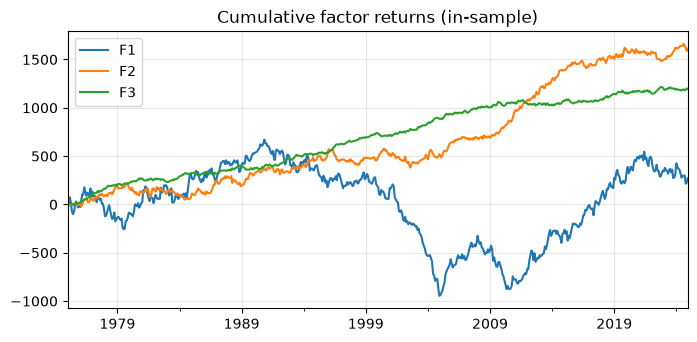

In [5]:
# With DataFrame input the labels are kept and can be used to label outputs
weights = pd.DataFrame(model.weights_, index=model.data_.assets, columns=["F1", "F2", "F3"])
factors = pd.DataFrame(model.factors_, index=model.data_.index, columns=weights.columns)
factors.cumsum().plot(title="Cumulative factor returns (in-sample)");

## 4. Out-of-sample use

Weights, betas and the factors' tangency portfolio are fixed on a training
sample and applied to new data. `evaluate(R_test)` reports out-of-sample
metrics; `loadings="projection"` switches to Lettau-Pelger's convention.

In [6]:
train, test = R.iloc[:400], R.iloc[400:]
m = lfm.RPPCA(3, gamma=10).fit(train)
pd.DataFrame(
    {
        "OLS betas (default)": m.evaluate(test),
        "projection loadings": m.evaluate(test, loadings="projection"),
    }
)

,OLS betas (default),projection loadings
sharpe_ratio,0.2215,0.2215
rms_alpha,0.2119,0.2158
unexplained_variation,0.3289,0.3307
total_r2,0.7152,0.7138


## 5. All estimators at a glance

In [7]:
data = sim.to_data("reference")  # returns + reference factors + XS target + macro
rows = {}
for est in [
    lfm.PCA(3),
    lfm.RPPCA(3, gamma=10),
    lfm.TSTargetPCA(3, gamma_ts=15),
    lfm.XSTargetPCA(3, gamma_xs=0.01),
    lfm.XSTSTargetPCA(3, gamma_xs=0.01, gamma_ts=15),
]:
    rows[type(est).__name__] = est.fit(data).evaluate()
pd.DataFrame(rows).T

,sharpe_ratio,rms_alpha,unexplained_variation,total_r2
PCA,0.3210,0.1311,0.3371,0.7060
RPPCA,0.3742,0.1221,0.3373,0.7058
TSTargetPCA,0.3814,0.1214,0.3374,0.7057
XSTargetPCA,0.3320,0.1284,0.3373,0.7059
XSTSTargetPCA,0.3585,0.1240,0.3374,0.7058


SPCA (needs observable factors) and IPCA (needs a characteristic panel) have
additional outputs; see notebooks 03 and 04. The registry lists everything that
can be created by name (used by the engine and the CLI):

In [8]:
lfm.available_models()

['ipca',
 'pca',
 'rppca',
 'spca',
 'ts_target_pca',
 'xs_target_pca',
 'xsts_target_pca']

## 6. Parallel execution

Cross-validation grids, rolling windows and bootstrap draws are independent
tasks run by an `Executor` with backends `"serial"`, `"thread"` or `"process"`
(`n_jobs=-1` = all cores). Results are reproducible and identical across
backends (independent random streams are spawned from one seed).

In [9]:
gs = lfm.GridSearchCV(
    lfm.RPPCA(3), {"gamma": [-1, 0, 5, 10, 20]}, cv=5, scoring="sharpe", executor="thread", n_jobs=4
).fit(R)
gs.best_params_, round(gs.best_score_, 4)

({'gamma': 5}, 0.2894)

## 7. Command line

The same functionality is available as `lfm` (or `python -m latent_factor_models`):

```bash
lfm models -v                                       # list estimators and parameters
lfm simulate -o synthetic_data                      # write CSV test data
lfm fit rppca --returns synthetic_data/returns.csv -p n_factors=3 -p gamma=10 -o out
lfm run examples/config_example.json --backend process --n-jobs -1
```

Inside Python the CLI entry point can be called directly:

In [10]:
from latent_factor_models.cli import main

main(["models"]);

ipca               IPCA           Instrumented principal components analysis.
pca                PCA            Statistical factors from the second-moment matrix of returns.
rppca              RPPCA          Risk-premium PCA.
spca               SPCA           Supervised PCA (Giglio, Xiu and Zhang).
ts_target_pca      TSTargetPCA    Time-series target PCA (Proposition 2).
xs_target_pca      XSTargetPCA    Cross-sectional target PCA (Proposition 1).
xsts_target_pca    XSTSTargetPCA  Combined cross-sectional and time-series target PCA (Proposition 3).
